done loading in fresnel equations
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red', 'test']
style object members:
 	 ['col', 'ls', 'printMembers']


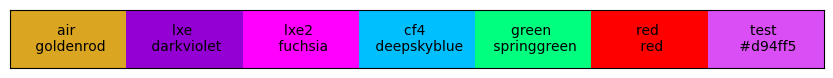

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

%run FresnelFunctions.py
%run MyStyle1.py
ShowMyStyles()
ms = MyStyleSet()
ms.SetMPLcolors()
ms.SetMPLcolors("on")

/Users/austindestcroix/Desktop/school_holders/projects/sbc/g4_cf4_updated/mySim/pythonHelpers


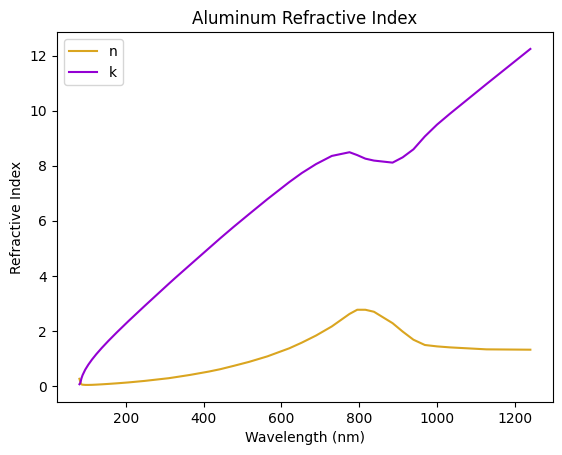

42

In [2]:


current_directory = os.getcwd()
print(current_directory)

# Load aluminum_n.txt
data_n = np.loadtxt('../data_nonG4/aluminum_n.txt', skiprows=1)
y_n = data_n[:, 1]
x_n = data_n[:, 0] * 1000  # Multiply x values by 1000

# Truncate data between 100 and 1200 along x
mask_n = (x_n >= 80) & (x_n <= 1300)
x_n = x_n[mask_n]
y_n = y_n[mask_n]

# Load aluminum_k.txt
data_k = np.loadtxt('../data_nonG4/aluminum_k.txt', skiprows=1)
y_k = data_k[:, 1]
x_k = data_k[:, 0] * 1000  # Multiply x values by 1000

mask_k = (x_k >= 80) & (x_k <= 1300)
x_k = x_k[mask_k]
y_k = y_k[mask_k]

# Save the modified data to new files
np.savetxt('../dataOptics/aluminum_n_short.txt', np.column_stack((x_n, y_n)), fmt='%.2f', delimiter='\t', header = "x(nm), y(n) - Rakic from refractiveindex.info")
np.savetxt('../dataOptics/aluminum_k_short.txt', np.column_stack((x_k, y_k)), fmt='%.2f', delimiter='\t', header = "x(nm), y(k) - Rakic from refractiveindex.info")

# Plot the data
plt.plot(x_n, y_n, label='n')
plt.plot(x_k, y_k, label='k')

# Add labels and title
plt.xlabel('Wavelength (nm)')
plt.ylabel('Refractive Index')
plt.title('Aluminum Refractive Index')

# Add legend
plt.legend()

# Show the plot
plt.show()

len(x_n)



In [3]:


# Interpolate n and k data
interp_n = interp1d(x_n, y_n, kind='linear')
interp_k = interp1d(x_k, y_k, kind='linear')
aluminum_full_nk = lambda wl: interp_n(wl) + 1j * interp_k(wl)


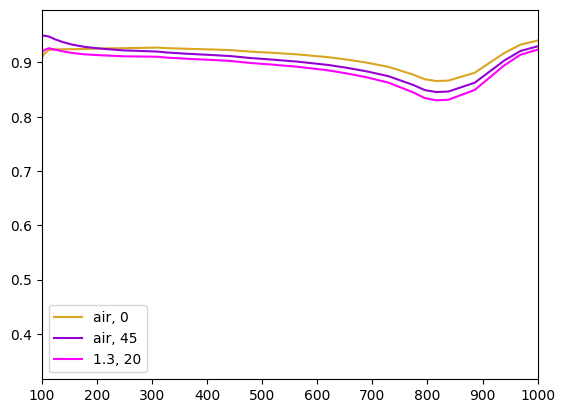

In [4]:
plt.plot(x_n, fresnel_Ref(n1 = 1.0, n2 = aluminum_full_nk(x_n), theta = 0.), label = "air, 0")
plt.plot(x_n, fresnel_Ref(n1 = 1.0, n2 = aluminum_full_nk(x_n), theta = 45), label = "air, 45")
plt.plot(x_n, fresnel_Ref(n1 = 1.3, n2 = aluminum_full_nk(x_n), theta = 0.), label = "1.3, 20")

# Save the x and y data to a text file
np.savetxt('../dataOptics/aluminum_calculatedRef.txt', np.column_stack((x_n, fresnel_Ref(n1=1.0, n2=aluminum_full_nk(x_n), theta=0.))), fmt='%.2f', delimiter='\t', header='wl(nm), Ref for aluminum, fresnel - air')

plt.legend()
plt.xlim(100, 1000)
plt.show()
